In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# To scale the data using z-score
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split

# Algorithms to use
from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import BaggingClassifier

from sklearn.ensemble import RandomForestClassifier

# Metrics to evaluate the model
from sklearn import metrics
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_curve,recall_score
from sklearn import tree


# For tuning the model
from sklearn.model_selection import GridSearchCV

# To ignore warnings
#import warnings
#warnings.filterwarnings("ignore")

In [43]:
# Cargar el dataset desde GitHub

url = "https://raw.githubusercontent.com/microcrafted/DatasetOnlineshoppers/main/online_shoppers_intention.csv"

df = pd.read_csv(url)

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [44]:
# Conocer las dimensiones del dataset
df.shape

(12330, 18)

In [45]:
# Mostrar información general del dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [46]:
# Contar las sesiones con compra y sin compra

df["Revenue"].value_counts()

,count
Revenue,
False,10422
True,1908


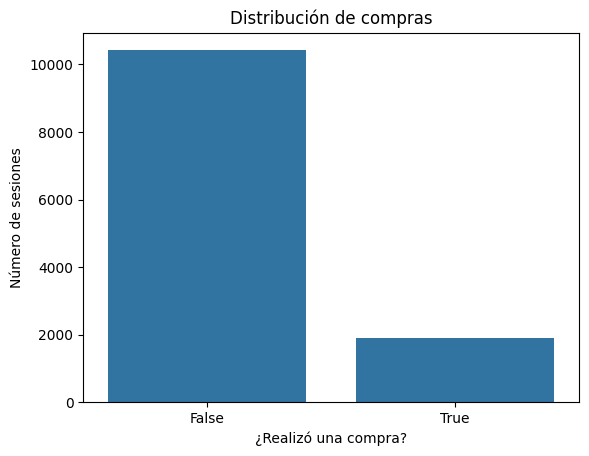

In [47]:
# Visualizar la distribución de Revenue

sns.countplot(data=df, x="Revenue")

plt.title("Distribución de compras")
plt.xlabel("¿Realizó una compra?")
plt.ylabel("Número de sesiones")

plt.show()

Interpretación: Se observa que el 84.53 % de las sesiones no terminaron en una compra, mientras que el 15.47 % sí. Esta diferencia indica un desbalance entre las clases, por lo que será necesario considerar métricas como Precision, Recall y F1-score para evaluar correctamente los modelos de clasificación.

In [48]:
# Comprobar registros duplicados

df.duplicated().sum()


np.int64(125)

In [49]:
# Crear una copia del dataset sin registros duplicados

df_limpio = df.drop_duplicates().reset_index(drop=True)

# Comprobar las nuevas dimensiones
df_limpio.shape

(12205, 18)

In [50]:
# Separar variables predictoras y variable objetivo

X = df_limpio.drop(columns=["Revenue"])

y = df_limpio["Revenue"]

# Comprobar las dimensiones
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (12205, 17)
Dimensiones de y: (12205,)


In [51]:
# Dividir los datos en entrenamiento y prueba

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Comprobar las dimensiones

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (9764, 17)
X_test: (2441, 17)
y_train: (9764,)
y_test: (2441,)


In [52]:
# Identificar las variables categóricas

columnas_categoricas = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

# Identificar las variables numéricas

columnas_numericas = [
    columna for columna in X_train.columns
    if columna not in columnas_categoricas
]

# Mostrar las columnas

print("Variables categóricas:")
print(columnas_categoricas)

print("\nVariables numéricas:")
print(columnas_numericas)

Variables categóricas:
['Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend']

Variables numéricas:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


In [53]:
# Importar herramientas de preprocesamiento

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Configurar el preprocesamiento

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), columnas_numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas)
    ]
)

print("Preprocesador configurado correctamente")

Preprocesador configurado correctamente


In [54]:
# Importar Pipeline
from sklearn.pipeline import Pipeline

# Crear el modelo de regresión logística
modelo_logistico = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", LogisticRegression(max_iter=1000, random_state=42))
    ]
)

# Entrenar el modelo
modelo_logistico.fit(X_train, y_train)

print("Modelo de regresión logística entrenado correctamente")

Modelo de regresión logística entrenado correctamente


In [55]:
# Importar herramientas de validación cruzada

from sklearn.model_selection import StratifiedKFold, cross_validate

# Configurar la validación cruzada de 5 grupos

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluar la regresión logística

resultados_logistico = cross_validate(
    modelo_logistico,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar los resultados promedio

print("Resultados de regresión logística:")

for metrica in ["accuracy", "precision", "recall", "f1"]:
    promedio = resultados_logistico["test_" + metrica].mean()
    print(f"{metrica}: {promedio:.4f}")

Resultados de regresión logística:
accuracy: 0.8818
precision: 0.7436
recall: 0.3722
f1: 0.4956


In [56]:
# Crear el modelo SVM

modelo_svm = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", SVC(kernel="rbf", C=1.0))
    ]
)

# Entrenar el modelo SVM

modelo_svm.fit(X_train, y_train)

print("Modelo SVM entrenado correctamente")

Modelo SVM entrenado correctamente


In [57]:
# Evaluar el modelo SVM mediante validación cruzada

resultados_svm = cross_validate(
    modelo_svm,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar los resultados promedio

print("Resultados de SVM:")

for metrica in ["accuracy", "precision", "recall", "f1"]:
    promedio = resultados_svm["test_" + metrica].mean()
    print(f"{metrica}: {promedio:.4f}")

Resultados de SVM:
accuracy: 0.8933
precision: 0.7482
recall: 0.4784
f1: 0.5833


In [58]:
# Crear el modelo de árbol de decisión

modelo_arbol = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", DecisionTreeClassifier(random_state=42))
    ]
)

# Entrenar el modelo

modelo_arbol.fit(X_train, y_train)

print("Modelo de árbol de decisión entrenado correctamente")

Modelo de árbol de decisión entrenado correctamente


In [59]:
# Evaluar el árbol de decisión mediante validación cruzada

resultados_arbol = cross_validate(
    modelo_arbol,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar los resultados promedio

print("Resultados del árbol de decisión:")

for metrica in ["accuracy", "precision", "recall", "f1"]:
    promedio = resultados_arbol["test_" + metrica].mean()
    print(f"{metrica}: {promedio:.4f}")

Resultados del árbol de decisión:
accuracy: 0.8617
precision: 0.5580
recall: 0.5682
f1: 0.5628


In [60]:
# Crear el modelo Bagging

modelo_bagging = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", BaggingClassifier(
            estimator=DecisionTreeClassifier(random_state=42),
            n_estimators=50,
            random_state=42
        ))
    ]
)

# Entrenar el modelo

modelo_bagging.fit(X_train, y_train)

print("Modelo Bagging entrenado correctamente")

Modelo Bagging entrenado correctamente


In [61]:
# Evaluar el modelo Bagging mediante validación cruzada

resultados_bagging = cross_validate(
    modelo_bagging,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar los resultados promedio

print("Resultados de Bagging:")

for metrica in ["accuracy", "precision", "recall", "f1"]:
    promedio = resultados_bagging["test_" + metrica].mean()
    print(f"{metrica}: {promedio:.4f}")

Resultados de Bagging:
accuracy: 0.9001
precision: 0.7269
recall: 0.5786
f1: 0.6441


In [62]:
# Crear el modelo Random Forest

modelo_rf = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("modelo", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Entrenar el modelo

modelo_rf.fit(X_train, y_train)

print("Modelo Random Forest entrenado correctamente")

Modelo Random Forest entrenado correctamente


In [63]:
# Evaluar Random Forest mediante validación cruzada

resultados_rf = cross_validate(
    modelo_rf,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Mostrar los resultados promedio

print("Resultados de Random Forest:")

for metrica in ["accuracy", "precision", "recall", "f1"]:
    promedio = resultados_rf["test_" + metrica].mean()
    print(f"{metrica}: {promedio:.4f}")

Resultados de Random Forest:
accuracy: 0.8995
precision: 0.7720
recall: 0.5072
f1: 0.6120


In [64]:
# Guardar los resultados de los cinco modelos

resultados_modelos = {
    "Regresión logística": resultados_logistico,
    "SVM": resultados_svm,
    "Árbol de decisión": resultados_arbol,
    "Bagging": resultados_bagging,
    "Random Forest": resultados_rf
}

# Crear la tabla comparativa

tabla_resultados = pd.DataFrame({
    nombre: {
        "Accuracy": resultados["test_accuracy"].mean(),
        "Precision": resultados["test_precision"].mean(),
        "Recall": resultados["test_recall"].mean(),
        "F1-score": resultados["test_f1"].mean()
    }
    for nombre, resultados in resultados_modelos.items()
}).T

# Convertir a porcentajes y ordenar por F1-score

tabla_resultados = (
    tabla_resultados * 100
).round(2).sort_values("F1-score", ascending=False)

# Mostrar la tabla

tabla_resultados

,Accuracy,Precision,Recall,F1-score
Bagging,90.01,72.69,57.86,64.41
Random Forest,89.95,77.20,50.72,61.20
SVM,89.33,74.82,47.84,58.33
Árbol de decisión,86.17,55.80,56.82,56.28
Regresión logística,88.18,74.36,37.22,49.56


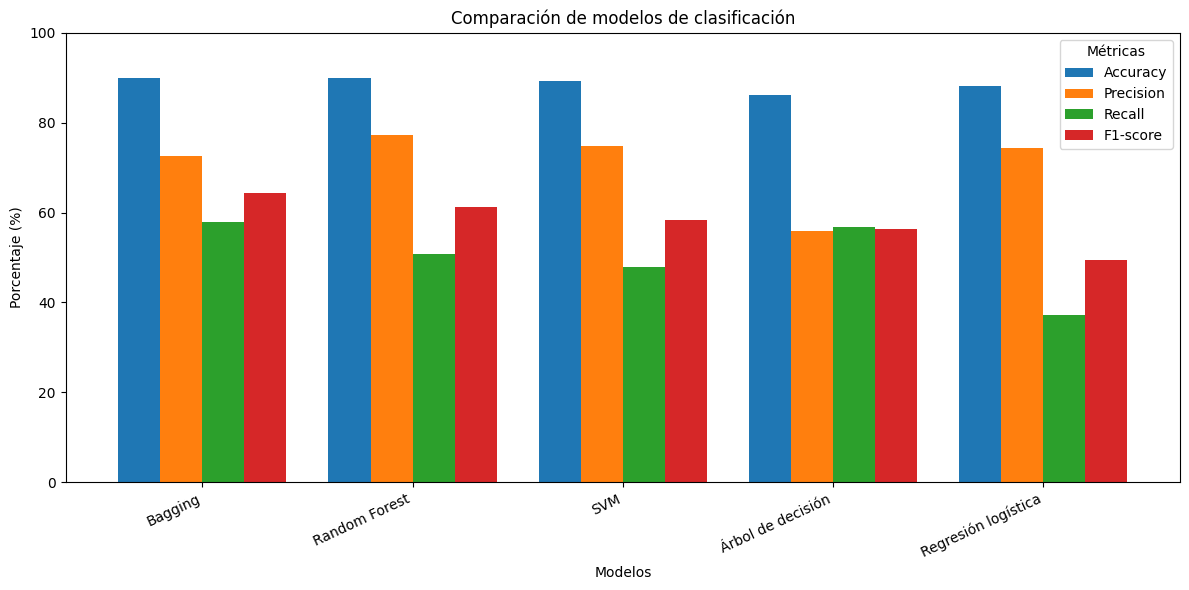

In [65]:
# Comparar gráficamente los cinco modelos

ax = tabla_resultados.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

# Personalizar la gráfica

plt.title("Comparación de modelos de clasificación")
plt.xlabel("Modelos")
plt.ylabel("Porcentaje (%)")

plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")

plt.legend(title="Métricas")
plt.tight_layout()

plt.show()

In [66]:
# Definir los parámetros que queremos probar

parametros_bagging = {
    "modelo__n_estimators": [30, 50],
    "modelo__estimator__max_depth": [8, None],
    "modelo__estimator__min_samples_leaf": [1, 5]
}

# Configurar la búsqueda de mejores parámetros

busqueda_bagging = GridSearchCV(
    estimator=modelo_bagging,
    param_grid=parametros_bagging,
    scoring="f1",
    cv=3,
    n_jobs=-1
)

# Ejecutar la búsqueda

busqueda_bagging.fit(X_train, y_train)

# Mostrar resultados

print("Mejor F1-score:", round(busqueda_bagging.best_score_, 4))

print("Mejores parámetros:")
print(busqueda_bagging.best_params_)

Mejor F1-score: 0.6484
Mejores parámetros:
{'modelo__estimator__max_depth': 8, 'modelo__estimator__min_samples_leaf': 1, 'modelo__n_estimators': 50}


In [67]:
# Definir parámetros para Random Forest

parametros_rf = {
    "modelo__n_estimators": [50, 100],
    "modelo__max_depth": [10, None],
    "modelo__class_weight": [None, "balanced"]
}

# Configurar GridSearchCV

busqueda_rf = GridSearchCV(
    estimator=modelo_rf,
    param_grid=parametros_rf,
    scoring="f1",
    cv=3,
    n_jobs=1
)

# Buscar los mejores parámetros

busqueda_rf.fit(X_train, y_train)

# Mostrar resultados

print("Mejor F1-score:", round(busqueda_rf.best_score_, 4))

print("Mejores parámetros:")
print(busqueda_rf.best_params_)

Mejor F1-score: 0.6671
Mejores parámetros:
{'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__n_estimators': 100}


In [68]:
# Seleccionar el mejor modelo de Random Forest

modelo_final = busqueda_rf.best_estimator_

# Realizar predicciones con los datos de prueba

y_pred = modelo_final.predict(X_test)

# Evaluar el modelo final

print("Resultados finales de Random Forest:")

print("Accuracy:", round(metrics.accuracy_score(y_test, y_pred), 4))

print("Precision:", round(metrics.precision_score(y_test, y_pred), 4))

print("Recall:", round(metrics.recall_score(y_test, y_pred), 4))

print("F1-score:", round(metrics.f1_score(y_test, y_pred), 4))

Resultados finales de Random Forest:
Accuracy: 0.8751
Precision: 0.5714
Recall: 0.8063
F1-score: 0.6688


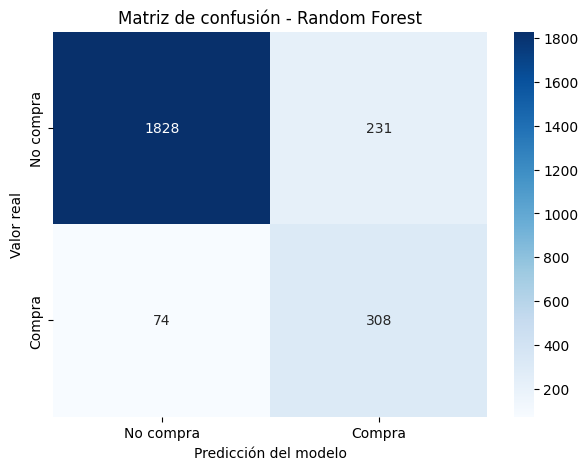

In [69]:
# Crear la matriz de confusión

matriz = confusion_matrix(y_test, y_pred, labels=[False, True])

# Graficar la matriz

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No compra", "Compra"],
    yticklabels=["No compra", "Compra"]
)

plt.title("Matriz de confusión - Random Forest")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")

plt.show()

La matriz de confusión del modelo Random Forest optimizado muestra que se clasificaron correctamente 2,136 de las 2,441 sesiones de prueba. El modelo identificó 308 de las 382 compras reales, alcanzando un Recall del 80.63 %. Sin embargo, produjo 231 falsos positivos, lo que refleja una limitación en la precisión de las predicciones de compra. Estos resultados evidencian un equilibrio entre detectar más compradores y reducir las falsas alarmas.

In [70]:
# Obtener la importancia de las variables

importancias = modelo_final.named_steps["modelo"].feature_importances_

# Obtener los nombres de las variables transformadas

nombres = modelo_final.named_steps["preprocesamiento"].get_feature_names_out()

# Crear una tabla de importancias

tabla_importancias = pd.DataFrame({
    "Variable": nombres,
    "Importancia": importancias
})

# Ordenar de mayor a menor importancia

tabla_importancias = tabla_importancias.sort_values(
    by="Importancia",
    ascending=False
)

# Mostrar las 10 variables más importantes

tabla_importancias.head(10)


,Variable,Importancia
8,numericas__PageValues,0.444531
7,numericas__ExitRates,0.100040
5,numericas__ProductRelated_Duration,0.066243
4,numericas__ProductRelated,0.051052
0,numericas__Administrative,0.043399
6,numericas__BounceRates,0.043077
1,numericas__Administrative_Duration,0.035385
17,categoricas__Month_Nov,0.030632
3,numericas__Informational_Duration,0.014027
16,categoricas__Month_May,0.012333


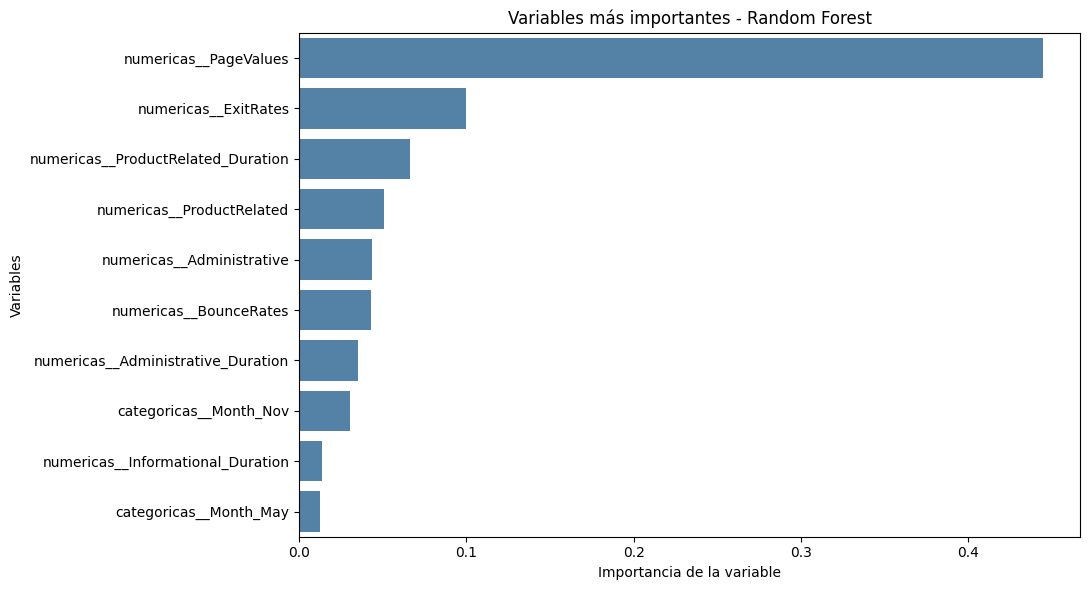

In [71]:
# Graficar las 10 variables más importantes

plt.figure(figsize=(11, 6))

sns.barplot(
    data=tabla_importancias.head(10),
    x="Importancia",
    y="Variable",
    color="steelblue"
)

plt.title("Variables más importantes - Random Forest")
plt.xlabel("Importancia de la variable")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

In [72]:
# Crear datos de entrenamiento sin PageValues

X_train_sin_page = X_train.drop(columns=["PageValues"])

# Actualizar la lista de variables numéricas

columnas_numericas_sin_page = [
    columna for columna in columnas_numericas
    if columna != "PageValues"
]

# Comprobar las dimensiones

print("Datos originales:", X_train.shape)

print("Datos sin PageValues:", X_train_sin_page.shape)

print("Variables numéricas:", len(columnas_numericas_sin_page))

Datos originales: (9764, 17)
Datos sin PageValues: (9764, 16)
Variables numéricas: 9


In [73]:
# Crear un preprocesador sin PageValues

preprocesador_sin_page = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), columnas_numericas_sin_page),
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), columnas_categoricas)
    ]
)

# Crear Random Forest sin PageValues

modelo_rf_sin_page = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador_sin_page),
        ("modelo", RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Modelo sin PageValues configurado correctamente")

Modelo sin PageValues configurado correctamente


In [74]:
# Evaluar Random Forest con PageValues

resultados_con_page = cross_validate(
    modelo_final,
    X_train,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Evaluar Random Forest sin PageValues

resultados_sin_page = cross_validate(
    modelo_rf_sin_page,
    X_train_sin_page,
    y_train,
    cv=validacion,
    scoring=["accuracy", "precision", "recall", "f1"]
)

# Crear tabla comparativa

comparacion_page = pd.DataFrame({
    "Con PageValues": {
        metrica: resultados_con_page["test_" + metrica].mean()
        for metrica in ["accuracy", "precision", "recall", "f1"]
    },
    "Sin PageValues": {
        metrica: resultados_sin_page["test_" + metrica].mean()
        for metrica in ["accuracy", "precision", "recall", "f1"]
    }
}).T

# Mostrar resultados en porcentajes

(comparacion_page * 100).round(2)

,accuracy,precision,recall,f1
Con PageValues,87.52,57.38,78.44,66.24
Sin PageValues,72.26,30.99,63.04,41.54


In [75]:
# Parámetros para Random Forest sin PageValues

parametros_rf_sin_page = {
    "modelo__max_depth": [5, 10],
    "modelo__min_samples_leaf": [1, 5],
    "modelo__class_weight": [None, "balanced"]
}

# Configurar GridSearchCV

busqueda_rf_sin_page = GridSearchCV(
    estimator=modelo_rf_sin_page,
    param_grid=parametros_rf_sin_page,
    scoring="f1",
    cv=3,
    n_jobs=1
)

# Buscar los mejores parámetros

busqueda_rf_sin_page.fit(X_train_sin_page, y_train)

# Mostrar resultados

print("Mejor F1-score sin PageValues:")
print(round(busqueda_rf_sin_page.best_score_, 4))

print("Mejores parámetros:")
print(busqueda_rf_sin_page.best_params_)

Mejor F1-score sin PageValues:
0.4153
Mejores parámetros:
{'modelo__class_weight': 'balanced', 'modelo__max_depth': 10, 'modelo__min_samples_leaf': 5}


In [76]:
# Comparar los modelos optimizados

comparacion_optimizados = pd.DataFrame({
    "Modelo": [
        "Random Forest con PageValues",
        "Random Forest sin PageValues"
    ],
    "F1-score": [
        busqueda_rf.best_score_,
        busqueda_rf_sin_page.best_score_
    ]
})

# Convertir los resultados a porcentajes

comparacion_optimizados["F1-score"] = (
    comparacion_optimizados["F1-score"] * 100
).round(2)

# Mostrar la tabla

comparacion_optimizados

,Modelo,F1-score
0,Random Forest con PageValues,66.71
1,Random Forest sin PageValues,41.53


## Resultados y conclusiones de clasificación

### Metodología

Se utilizó el dataset Online Shoppers Purchasing Intention para estudiar la clasificación de sesiones de navegación según la variable Revenue, que indica si una sesión terminó en compra. El conjunto original contenía 12,330 registros y 18 columnas. Tras eliminar 125 registros duplicados, se trabajó con 12,205 registros.

Los datos se dividieron de manera estratificada: 80 % para entrenamiento (9,764 registros) y 20 % para prueba (2,441 registros). Se aplicó estandarización a variables numéricas y codificación One-Hot a variables categóricas mediante Pipeline.

### Comparación de modelos

Se evaluaron cinco clasificadores mediante validación cruzada de cinco divisiones: regresión logística, SVM, árbol de decisión, Bagging y Random Forest. En la comparación inicial, Bagging obtuvo el mayor F1-score (64.41 %), mientras que Random Forest alcanzó la mayor Precision (77.20 %).

### Optimización y evaluación final

Se optimizaron Bagging y Random Forest mediante GridSearchCV. Random Forest obtuvo el mejor F1-score de validación en la búsqueda de parámetros (66.71 %), utilizando 100 árboles, profundidad máxima de 10 y pesos balanceados para las clases.

La evaluación final de Random Forest con 2,441 registros de prueba obtuvo Accuracy de 87.51 %, Precision de 57.14 %, Recall de 80.63 % y F1-score de 66.88 %. La matriz de confusión registró 1,828 verdaderos negativos, 231 falsos positivos, 74 falsos negativos y 308 verdaderos positivos.

### Interpretación y limitaciones

El modelo logró identificar 308 de las 382 compras reales del conjunto de prueba. Sin embargo, también generó 231 falsas predicciones de compra, lo que muestra un compromiso entre Recall y Precision.

La característica más importante fue PageValues, con una importancia estimada de 44.45 %. En una búsqueda adicional de parámetros usando tres divisiones de validación cruzada, el mejor F1-score fue 66.71 % con PageValues y 41.53 % sin esa característica. Esto evidencia una dependencia importante de dicha variable.

Dado que el objetivo del proyecto es anticipar compras antes de que ocurran, se reconoce una limitación: el dataset contiene resúmenes de sesiones completas y no permite confirmar qué variables estaban disponibles en cada instante anterior a la compra. Por ello, los resultados constituyen una evaluación de clasificación de sesiones y una base exploratoria para futuros modelos de predicción anticipada. Para validar una aplicación en tiempo real se necesitarían registros cronológicos de navegación.